# Floor 3 Smart Building Analysis

This notebook analyses only Floor 3 data from 2018 and 2019. The analysis will first establish data quality, then compare energy demand and indoor-environment patterns before considering anomaly detection or forecasting.

The source is sampled at approximately one-minute intervals. Hourly summaries will be used for readable comparisons, while the raw minute-level data will be retained for validation.

## 1. Setup and scope

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 140)
plt.rcParams['figure.figsize'] = (12, 4)

DATA_DIR = Path('../data')
SOURCE_FILES = {
    2018: DATA_DIR / '2018Floor3.csv',
    2019: DATA_DIR / '2019Floor3.csv',
}
DATE_COL = 'Date'

assert all(path.exists() for path in SOURCE_FILES.values()), 'Both Floor 3 CSV files must exist.'
print('Analysing:', ', '.join(path.name for path in SOURCE_FILES.values()))

Analysing: 2018Floor3.csv, 2019Floor3.csv


## 2. Load and validate the two Floor 3 files

In [2]:
frames = []
file_audits = []

for year, path in SOURCE_FILES.items():
    frame = pd.read_csv(path)
    frame['year'] = year
    frame['source_file'] = path.name
    frames.append(frame)
    file_audits.append({
        'year': year,
        'file': path.name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'date_min_raw': frame[DATE_COL].min(),
        'date_max_raw': frame[DATE_COL].max(),
    })

floor3 = pd.concat(frames, ignore_index=True)
floor3[DATE_COL] = pd.to_datetime(floor3[DATE_COL], errors='coerce')
floor3 = floor3.sort_values(DATE_COL).reset_index(drop=True)

print('File audit')
display(pd.DataFrame(file_audits))
print('Combined shape:', floor3.shape)
print('Columns:')
print(floor3.columns.tolist())
print('Parsed date range:', floor3[DATE_COL].min(), 'to', floor3[DATE_COL].max())
display(floor3.head(3))

File audit


,year,file,rows,columns,date_min_raw,date_max_raw
0,2018,2018Floor3.csv,264960,32,2018-07-01 00:00:00,2018-12-31 23:59:00
1,2019,2019Floor3.csv,525600,32,2019-01-01 00:00:00,2019-12-31 23:59:00


Combined shape: (790560, 32)
Columns:
['Date', 'z1_AC1(kW)', 'z1_AC2(kW)', 'z1_AC3(kW)', 'z1_AC4(kW)', 'z1_Light(kW)', 'z1_Plug(kW)', 'z1_S1(degC)', 'z1_S1(RH%)', 'z1_S1(lux)', 'z2_AC1(kW)', 'z2_Light(kW)', 'z2_Plug(kW)', 'z2_S1(degC)', 'z2_S1(RH%)', 'z2_S1(lux)', 'z3_Light(kW)', 'z3_Plug(kW)', 'z4_AC1(kW)', 'z4_Light(kW)', 'z4_Plug(kW)', 'z4_S1(degC)', 'z4_S1(RH%)', 'z4_S1(lux)', 'z5_AC1(kW)', 'z5_Light(kW)', 'z5_Plug(kW)', 'z5_S1(degC)', 'z5_S1(RH%)', 'z5_S1(lux)', 'year', 'source_file']
Parsed date range: 2018-07-01 00:00:00 to 2019-12-31 23:59:00


,Date,z1_AC1(kW),z1_AC2(kW),z1_AC3(kW),z1_AC4(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z4_AC1(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux),year,source_file
0,2018-07-01 00:00:00,0.0,0.0,0.0,0.07,0.0,0.03,28.44,60.67,0.0,0.0,0.0,0.03,27.67,63.37,0.0,0.01,0.26,0.0,0.0,0.02,27.69,65.66,0.0,0.0,0.0,0.02,26.88,71.16,0.0,2018,2018Floor3.csv
1,2018-07-01 00:01:00,0.0,0.0,0.0,0.07,0.0,0.03,28.44,60.67,0.0,0.0,0.0,0.03,27.67,63.37,0.0,0.02,0.37,0.0,0.0,0.02,27.69,65.65,0.0,0.0,0.0,0.02,26.88,71.16,0.0,2018,2018Floor3.csv
2,2018-07-01 00:02:00,0.0,0.0,0.0,0.07,0.0,0.03,28.45,60.67,0.0,0.0,0.0,0.03,27.67,63.37,0.0,0.01,0.32,0.0,0.0,0.02,27.69,65.63,0.0,0.0,0.0,0.02,26.88,71.18,0.0,2018,2018Floor3.csv


In [3]:
numeric_cols = floor3.select_dtypes(include='number').columns.tolist()
missing_summary = (
    floor3.groupby('year')[numeric_cols]
    .apply(lambda group: group.isna().sum())
)
missing_pct = (missing_summary.div(floor3.groupby('year').size(), axis=0) * 100).round(2)

duplicate_timestamps = floor3.duplicated([DATE_COL]).sum()
intervals = floor3[DATE_COL].dropna().sort_values().diff().dropna()
gap_summary = intervals.value_counts().head(10).rename_axis('interval').reset_index(name='count')
long_gaps = intervals[intervals > pd.Timedelta(minutes=1)]

print('Missing values by year (%)')
display(missing_pct.T)
print('Duplicate timestamps:', duplicate_timestamps)
print('Most common timestamp intervals:')
display(gap_summary)
print('Intervals longer than one minute:', len(long_gaps))
if len(long_gaps):
    print('Largest gaps:')
    display(long_gaps.sort_values(ascending=False).head(10))

Missing values by year (%)


year,2018,2019
z1_AC1(kW),25.30,0.74
z1_AC2(kW),25.30,0.74
z1_AC3(kW),25.30,0.74
z1_AC4(kW),22.50,8.21
z1_Light(kW),22.36,0.12
z1_Plug(kW),22.33,0.11
z1_S1(degC),61.75,24.44
z1_S1(RH%),61.75,24.45
z1_S1(lux),61.75,24.45
z2_AC1(kW),22.50,8.21


Duplicate timestamps: 0
Most common timestamp intervals:


,interval,count
0,0 days 00:01:00,790559


Intervals longer than one minute: 0


In [4]:
# Range checks are deliberately descriptive; no values are removed at this stage.
range_summary = floor3[numeric_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
range_summary['negative_count'] = (floor3[numeric_cols] < 0).sum()
range_summary['zero_count'] = (floor3[numeric_cols] == 0).sum()
display(range_summary[['count', 'min', '1%', '50%', '99%', 'max', 'negative_count', 'zero_count']])

,count,min,1%,50%,99%,max,negative_count,zero_count
z1_AC1(kW),719633.0,0.00,0.00,0.00,0.0000,2.35,0,717497
z1_AC2(kW),719633.0,0.00,0.00,0.00,0.0000,5.42,0,713617
z1_AC3(kW),719633.0,0.00,0.00,0.00,0.0000,2.26,0,714443
z1_AC4(kW),687770.0,0.00,0.00,0.07,36.0100,55.95,0,307204
z1_Light(kW),730710.0,0.00,0.00,0.00,5.8000,162.24,0,398454
z1_Plug(kW),730827.0,0.00,0.02,0.08,1.3200,35.45,0,101
z1_S1(degC),498458.0,17.90,20.49,25.79,29.5800,30.90,0,0
z1_S1(RH%),498456.0,48.57,51.59,60.84,73.7545,80.62,0,0
z1_S1(lux),498453.0,0.00,0.00,0.00,44.0000,80.00,0,249416
z2_AC1(kW),687781.0,0.00,0.00,0.00,26.4600,59.07,0,547671


### Initial interpretation

The audit above is the gate for the rest of the notebook. Missing sensors, timestamp gaps, and suspicious ranges will be carried into later summaries rather than silently converted into zeros or discarded.

## 3. Build hourly Floor 3 features

The source columns are zone-level measurements. We calculate component demand as the row-wise sum of available sensors and retain a contributor count for every component. These are hourly mean demands in kW, not energy totals in kWh.

In [6]:
sensor_cols = [column for column in floor3.columns if column not in {DATE_COL, 'year', 'source_file'}]
component_cols = {
    'ac_kw': [column for column in sensor_cols if '_AC' in column and column.endswith('(kW)')],
    'light_kw': [column for column in sensor_cols if '_Light' in column and column.endswith('(kW)')],
    'plug_kw': [column for column in sensor_cols if '_Plug' in column and column.endswith('(kW)')],
}
print('Component columns')
for component, columns in component_cols.items():
    print(f'{component}: {columns}')

for component, columns in component_cols.items():
    floor3[component] = floor3[columns].sum(axis=1, min_count=1)
    floor3[f'{component}_contributors'] = floor3[columns].notna().sum(axis=1)

floor3['total_demand_kw'] = floor3[['ac_kw', 'light_kw', 'plug_kw']].sum(axis=1, min_count=1)
floor3['total_demand_contributors'] = floor3[['ac_kw', 'light_kw', 'plug_kw']].notna().sum(axis=1)

hourly = (
    floor3.set_index(DATE_COL)
    .groupby('year')[[column for column in floor3.columns if column not in {DATE_COL, 'year', 'source_file'}]]
    .resample('1h')
    .mean()
    .reset_index()
)
hourly['month'] = hourly[DATE_COL].dt.month
hourly['hour'] = hourly[DATE_COL].dt.hour
hourly['day_of_week'] = hourly[DATE_COL].dt.day_name()
hourly['is_weekend'] = hourly[DATE_COL].dt.dayofweek >= 5

print('Hourly shape:', hourly.shape)
display(hourly.groupby('year')[['ac_kw', 'light_kw', 'plug_kw', 'total_demand_kw']].agg(['count', 'mean', 'median', 'max']).round(3))

Component columns
ac_kw: ['z1_AC1(kW)', 'z1_AC2(kW)', 'z1_AC3(kW)', 'z1_AC4(kW)', 'z2_AC1(kW)', 'z4_AC1(kW)', 'z5_AC1(kW)']
light_kw: ['z1_Light(kW)', 'z2_Light(kW)', 'z3_Light(kW)', 'z4_Light(kW)', 'z5_Light(kW)']
plug_kw: ['z1_Plug(kW)', 'z2_Plug(kW)', 'z3_Plug(kW)', 'z4_Plug(kW)', 'z5_Plug(kW)']
Hourly shape: (13176, 43)


ac_kw                         light_kw                       plug_kw                      total_demand_kw                        
     count    mean median      max    count   mean median     max   count   mean median    max           count    mean median      max
year                                                                                                                                  
2018  3433  13.868   0.07  105.948     3445  6.219  0.282  36.861    3446  1.413  0.536  6.192            3446  21.436  0.859  126.166
2019  8757  13.116   0.00  117.991     8757  6.090  0.445  28.211    8757  1.454  0.706  8.690            8757  20.658  1.166  137.724

In [7]:
energy_summary = (
    hourly.groupby('year')[['ac_kw', 'light_kw', 'plug_kw', 'total_demand_kw']]
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .round(3)
)
print('Hourly demand summary (kW)')
display(energy_summary)

profile = (
    hourly.groupby(['year', 'is_weekend', 'hour'])[['ac_kw', 'light_kw', 'plug_kw', 'total_demand_kw']]
    .mean()
)
print('Highest average-demand hours by year and weekday/weekend')
display(profile['total_demand_kw'].groupby(level=[0, 1], group_keys=False).nlargest(5).round(3))

Hourly demand summary (kW)


ac_kw                              light_kw                            plug_kw                            total_demand_kw         \
        mean median     std  min      max     mean median    std  min     max    mean median    std   min    max            mean median   
year                                                                                                                                      
2018  13.868   0.07  26.083  0.0  105.948    6.219  0.282  7.441  0.0  36.861   1.413  0.536  1.315  0.00  6.192          21.436  0.859   
2019  13.116   0.00  26.634  0.0  117.991    6.090  0.445  7.268  0.0  28.211   1.454  0.706  1.176  0.04  8.690          20.658  1.166   

                              
         std    min      max  
year                          
2018  33.050  0.000  126.166  
2019  33.036  0.138  137.724

Highest average-demand hours by year and weekday/weekend


year  is_weekend  hour
2018  False       8       94.703
                  13      92.194
                  9       80.352
                  14      77.875
                  10      77.742
      True        11       4.554
                  12       4.515
                  13       4.508
                  10       4.436
                  14       4.376
2019  False       8       89.347
                  13      83.917
                  9       77.390
                  14      74.614
                  10      73.941
      True        10       5.127
                  13       5.023
                  14       5.010
                  9        4.645
                  11       4.608
Name: total_demand_kw, dtype: float64

### Interpretation checkpoint

The next plots will test whether the summary differences are stable operating patterns or isolated sensor events. Because Floor 3 has different sensor availability by zone, contributor counts will be shown alongside component trends when data quality affects interpretation.

## 4. Visual comparison of operating patterns

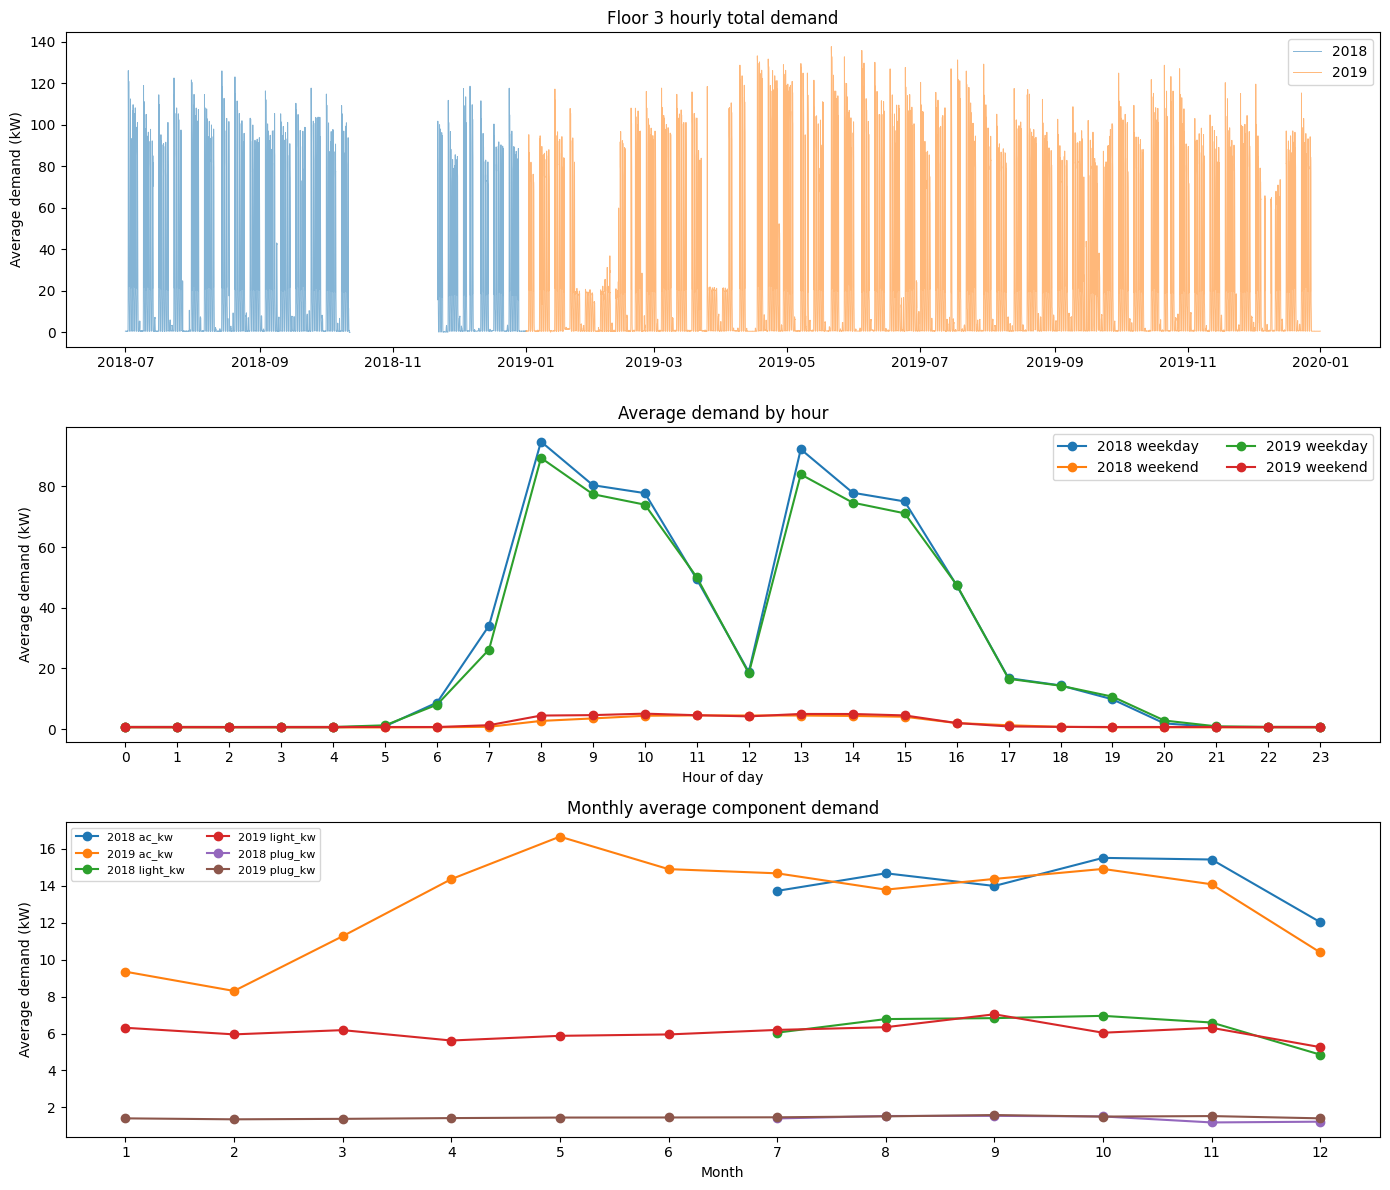

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=False)

for year, group in hourly.groupby('year'):
    axes[0].plot(group[DATE_COL], group['total_demand_kw'], alpha=0.55, linewidth=0.7, label=str(year))
axes[0].set_title('Floor 3 hourly total demand')
axes[0].set_ylabel('Average demand (kW)')
axes[0].legend()

profile_plot = hourly.groupby(['year', 'is_weekend', 'hour'])['total_demand_kw'].mean().reset_index()
for (year, is_weekend), group in profile_plot.groupby(['year', 'is_weekend']):
    label = f'{year} ' + ('weekend' if is_weekend else 'weekday')
    axes[1].plot(group['hour'], group['total_demand_kw'], marker='o', linewidth=1.5, label=label)
axes[1].set_title('Average demand by hour')
axes[1].set_xlabel('Hour of day')
axes[1].set_ylabel('Average demand (kW)')
axes[1].set_xticks(range(24))
axes[1].legend(ncol=2)

monthly = hourly.groupby(['year', 'month'])[['ac_kw', 'light_kw', 'plug_kw']].mean().reset_index()
for component in ['ac_kw', 'light_kw', 'plug_kw']:
    for year, group in monthly.groupby('year'):
        axes[2].plot(group['month'], group[component], marker='o', label=f'{year} {component}')
axes[2].set_title('Monthly average component demand')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('Average demand (kW)')
axes[2].set_xticks(range(1, 13))
axes[2].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

## 5. Interpretable baseline and anomaly candidates

An anomaly candidate is defined here as an hourly demand value whose absolute residual from the typical demand for the same year, hour, and weekday/weekend status is unusually large. This is a screening method for investigation, not proof of equipment failure or occupancy.

In [9]:
baseline_keys = ['year', 'is_weekend', 'hour']
hourly['baseline_kw'] = hourly.groupby(baseline_keys)['total_demand_kw'].transform('median')
hourly['residual_kw'] = hourly['total_demand_kw'] - hourly['baseline_kw']

residual_scale = hourly.groupby('year')['residual_kw'].transform(
    lambda values: (values - values.median()).abs().median()
)
hourly['anomaly_threshold_kw'] = 6 * residual_scale.replace(0, np.nan)
hourly['is_anomaly_candidate'] = hourly['residual_kw'].abs() > hourly['anomaly_threshold_kw']

anomaly_summary = hourly.groupby('year').agg(
    hours=('total_demand_kw', 'count'),
    candidate_hours=('is_anomaly_candidate', 'sum'),
    candidate_rate=('is_anomaly_candidate', 'mean'),
    largest_absolute_residual_kw=('residual_kw', lambda values: values.abs().max()),
)
anomaly_summary['candidate_rate'] = (anomaly_summary['candidate_rate'] * 100).round(2)
print('Baseline anomaly screening summary')
display(anomaly_summary.round(3))

candidate_events = (
    hourly.loc[hourly['is_anomaly_candidate'], [DATE_COL, 'year', 'total_demand_kw', 'baseline_kw', 'residual_kw', 'total_demand_contributors']]
    .sort_values('residual_kw', key=lambda values: values.abs(), ascending=False)
    .head(20)
)
print('Largest candidate events for inspection')
display(candidate_events.round(3))

Baseline anomaly screening summary


,hours,candidate_hours,candidate_rate,largest_absolute_residual_kw
year,,,,
2018,3446,854,19.34,98.235
2019,8757,2258,25.78,97.384


Largest candidate events for inspection


,Date,year,total_demand_kw,baseline_kw,residual_kw,total_demand_contributors
1045,2018-08-13 13:00:00,2018,0.578,98.813,-98.235,3.0
4405,2018-12-31 13:00:00,2018,0.599,98.813,-98.214,3.0
3781,2018-12-05 13:00:00,2018,0.680,98.813,-98.133,3.0
637,2018-07-27 13:00:00,2018,0.831,98.813,-97.982,3.0
3901,2018-12-10 13:00:00,2018,0.999,98.813,-97.814,3.0
709,2018-07-30 13:00:00,2018,1.344,98.813,-97.469,3.0
6920,2019-04-15 08:00:00,2019,0.554,97.938,-97.384,3.0
4424,2019-01-01 08:00:00,2019,0.569,97.938,-97.369,3.0
6944,2019-04-16 08:00:00,2019,0.573,97.938,-97.365,3.0
13160,2019-12-31 08:00:00,2019,0.577,97.938,-97.361,3.0


## 6. Current findings and limitations

- The two Floor 3 files have a consistent one-minute timestamp cadence and no duplicate timestamps.
- 2018 contains substantially more missing sensor readings than 2019, so year comparisons must include coverage caveats.
- Weekday demand is much higher than weekend demand, suggesting a strong operating-schedule pattern.
- AC contributes the largest average component demand, while lighting and plug loads are more stable and smaller on average.
- Extreme values and high residuals are candidates for inspection, not automatic faults. They should be checked against sensor missingness, contributor counts, and the raw minute-level data.
- The 2018 file covers July through December, while 2019 covers the full year. Direct annual comparisons are therefore incomplete; month-matched comparisons are more defensible.

No occupancy or causal conclusion is made because the dataset does not provide occupancy labels or equipment-fault labels.

## 7. Conservative cleaning for analysis

This section creates an analytical copy instead of changing the raw `floor3` data. The goal is to remove only values that are physically impossible for the recorded quantity: negative power/light/plug readings, temperatures outside a broad building-sensor range, relative humidity outside 0-100%, and negative lux. Large but possible values are retained and flagged because automatically deleting them could remove real peak demand.

The result should be interpreted as a quality-controlled analysis view, not as proof that every remaining value is correct. Missing values are not blanket-imputed; contributor counts and coverage remain part of later summaries.

In [10]:
analysis_floor3 = floor3.copy()
quality_flags = pd.DataFrame(index=analysis_floor3.index)

power_cols = [column for column in sensor_cols if any(label in column for label in ['_AC', '_Light', '_Plug'])]
temperature_cols = [column for column in sensor_cols if 'degC' in column]
humidity_cols = [column for column in sensor_cols if 'RH%' in column]
lux_cols = [column for column in sensor_cols if 'lux' in column]

quality_flags['negative_power_or_light'] = (analysis_floor3[power_cols] < 0).any(axis=1)
quality_flags['temperature_out_of_range'] = ((analysis_floor3[temperature_cols] < 10) | (analysis_floor3[temperature_cols] > 40)).any(axis=1)
quality_flags['humidity_out_of_range'] = ((analysis_floor3[humidity_cols] < 0) | (analysis_floor3[humidity_cols] > 100)).any(axis=1)
quality_flags['negative_lux'] = (analysis_floor3[lux_cols] < 0).any(axis=1)
quality_flags['any_hard_quality_issue'] = quality_flags.any(axis=1)

for column in power_cols + lux_cols:
    analysis_floor3.loc[analysis_floor3[column] < 0, column] = np.nan
for column in temperature_cols:
    analysis_floor3.loc[(analysis_floor3[column] < 10) | (analysis_floor3[column] > 40), column] = np.nan
for column in humidity_cols:
    analysis_floor3.loc[(analysis_floor3[column] < 0) | (analysis_floor3[column] > 100), column] = np.nan

print('Hard quality flags')
display(quality_flags.mean().mul(100).round(4).rename('percentage_of_rows'))
print('Raw rows retained:', len(floor3), '| Analytical rows retained:', len(analysis_floor3))

Hard quality flags


negative_power_or_light     0.0
temperature_out_of_range    0.0
humidity_out_of_range       0.0
negative_lux                0.0
any_hard_quality_issue      0.0
Name: percentage_of_rows, dtype: float64

Raw rows retained: 790560 | Analytical rows retained: 790560


## 8. Matched-month comparison and load-share normalisation

2018 contains July to December, while 2019 contains the full year. This section therefore compares only July-December across both years. This calendar restriction makes the comparison more defensible, but it does not remove differences in weather, holidays, or sensor coverage.

Load shares divide each component by total demand. Shares describe the composition of demand, not the amount of energy consumed. Rows with missing or near-zero total demand receive missing shares rather than artificial percentages.

In [13]:
matched_hourly = hourly.loc[hourly['month'].between(7, 12)].copy()
matched_hourly['complete_component_coverage'] = (
    matched_hourly[['ac_kw', 'light_kw', 'plug_kw']].notna().sum(axis=1) == 3
)
matched_hourly['total_demand_for_share_kw'] = matched_hourly['total_demand_kw'].where(
    matched_hourly['complete_component_coverage'] & (matched_hourly['total_demand_kw'] > 0.01)
)
for component in ['ac_kw', 'light_kw', 'plug_kw']:
    matched_hourly[f'{component}_share'] = matched_hourly[component] / matched_hourly['total_demand_for_share_kw']

summary_metrics = {}
for component in ['ac_kw', 'light_kw', 'plug_kw', 'total_demand_kw']:
    summary_metrics[component] = {
        'mean_kw': matched_hourly.groupby('year')[component].mean(),
        'median_kw': matched_hourly.groupby('year')[component].median(),
        'iqr_kw': matched_hourly.groupby('year')[component].quantile(0.75) - matched_hourly.groupby('year')[component].quantile(0.25),
        'p90_kw': matched_hourly.groupby('year')[component].quantile(0.90),
        'p95_kw': matched_hourly.groupby('year')[component].quantile(0.95),
        'p99_kw': matched_hourly.groupby('year')[component].quantile(0.99),
    }
matched_summary = pd.DataFrame({
    (component, metric): values
    for component, metrics in summary_metrics.items()
    for metric, values in metrics.items()
}).round(3)

share_summary = matched_hourly.groupby('year')[[f'{component}_share' for component in ['ac_kw', 'light_kw', 'plug_kw']]].mean().round(3)
coverage_summary = matched_hourly.groupby('year').agg(
    average_component_contributors=('total_demand_contributors', 'mean'),
    complete_component_hours=('complete_component_coverage', 'sum'),
    complete_component_rate=('complete_component_coverage', 'mean'),
).round(3)
coverage_summary['complete_component_rate'] = (coverage_summary['complete_component_rate'] * 100).round(2)

print('Matched-month demand summary: July-December only')
display(matched_summary)
print('Average demand composition shares')
display(share_summary)
print('Average component contributor count')
display(coverage_summary)

Matched-month demand summary: July-December only


ac_kw                                           light_kw                                           plug_kw                          \
     mean_kw median_kw  iqr_kw  p90_kw  p95_kw  p99_kw  mean_kw median_kw  iqr_kw  p90_kw  p95_kw  p99_kw mean_kw median_kw iqr_kw p90_kw   
year                                                                                                                                        
2018  13.868      0.07  17.046  62.079  73.096  89.644    6.219     0.282  15.359  17.225  17.556  18.055   1.413     0.536  2.084  3.675   
2019  13.701      0.00  10.329  62.115  72.098  92.289    6.194     0.889  15.381  16.603  16.969  17.610   1.498     0.735  1.996  3.423   

                   total_demand_kw                                             
     p95_kw p99_kw         mean_kw median_kw  iqr_kw  p90_kw  p95_kw   p99_kw  
year                                                                           
2018  3.856  4.174          21.436     0.859  28.913  83.008  93.546  109.478  
2019  3.556  3.840          21.389     1.606  22.144  81.888  91.644  111.553

Average demand composition shares


,ac_kw_share,light_kw_share,plug_kw_share
year,,,
2018,0.247,0.315,0.438
2019,0.184,0.326,0.491


Average component contributor count


,average_component_contributors,complete_component_hours,complete_component_rate
year,,,
2018,2.330,3433,77.7
2019,2.996,4413,99.9


### How to read the normalised results

Use the matched-month table to compare typical and upper-tail demand in the same calendar window. Use the share table to ask which system dominates the demand mix. A difference in shares does not necessarily mean that a component consumed more in absolute terms; the raw kW summaries must be checked alongside it. Coverage values below the expected number of components indicate that missing sensors may affect interpretation.

## 9. Daily load-shape features

This section compresses hourly demand into daily indicators that are easier to compare across dates. The daily energy value is an approximation obtained by summing hourly mean kW values over 24 hours; it is not a direct meter reading. Peak-to-baseload ratio and ramp magnitude describe operating shape, while the 90th-percentile count identifies unusually high-demand hours relative to each year's distribution.

In [12]:
hourly_shape = hourly.sort_values(DATE_COL).copy()
hourly_shape['date'] = hourly_shape[DATE_COL].dt.date
year_p90 = hourly_shape.groupby('year')['total_demand_kw'].transform(lambda values: values.quantile(0.90))
hourly_shape['above_year_p90'] = hourly_shape['total_demand_kw'] > year_p90
hourly_shape['hourly_ramp_kw'] = hourly_shape.groupby('year')['total_demand_kw'].diff().abs()

daily_shape = hourly_shape.groupby(['year', 'date']).agg(
    approximate_daily_energy_kwh=('total_demand_kw', 'sum'),
    peak_demand_kw=('total_demand_kw', 'max'),
    baseload_kw=('total_demand_kw', 'min'),
    peak_hours=('above_year_p90', 'sum'),
    maximum_hourly_ramp_kw=('hourly_ramp_kw', 'max'),
    observed_hours=('total_demand_kw', 'count'),
).reset_index()
daily_shape['peak_to_baseload_ratio'] = daily_shape['peak_demand_kw'] / daily_shape['baseload_kw'].where(daily_shape['baseload_kw'] > 0.01)

print('Daily load-shape summary')
display(daily_shape.groupby('year')[['approximate_daily_energy_kwh', 'peak_demand_kw', 'peak_to_baseload_ratio', 'maximum_hourly_ramp_kw', 'observed_hours']].agg(['median', 'mean', 'max']).round(3))

Daily load-shape summary


approximate_daily_energy_kwh                    peak_demand_kw                  peak_to_baseload_ratio                    \
                           median     mean       max         median    mean      max                 median     mean      max   
year                                                                                                                            
2018                      658.368  401.461   900.821         95.924  69.624  126.166                166.939  131.962  667.674   
2019                      699.917  495.631  1064.803         90.883  66.490  137.724                128.736   97.842  233.674   

     maximum_hourly_ramp_kw                  observed_hours              
                     median    mean      max         median    mean max  
year                                                                     
2018                 72.508  54.205  100.336           24.0  18.728  24  
2019                 69.157  50.574  111.860           24.0  23.992  24